In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [5]:
url = "/content/student_dropout_behavior_dataset.csv"

df = pd.read_csv(url)

print("Dataset berhasil dibaca!")
print("Jumlah baris dan kolom:", df.shape)

display(df.head())


Dataset berhasil dibaca!
Jumlah baris dan kolom: (300, 16)


,student_id,name,age,gender,quiz1_marks,quiz2_marks,quiz3_marks,total_assignments,assignments_submitted,midterm_marks,final_marks,previous_gpa,total_lectures,lectures_attended,total_lab_sessions,labs_attended
0,1,Kristina Vaughan,19,Male,8.0,5.7,7.4,5,NaN,30.0,36.5,2.57,12,4,6,1
1,2,Rodney Daniels,21,Male,10.0,7.9,4.1,5,NaN,25.4,33.0,2.40,12,1,6,5
2,3,Jose Nash,19,Female,7.5,1.2,0.3,5,NaN,14.4,24.8,2.99,12,0,6,0
3,4,Nicole Martin,21,Male,5.2,2.5,9.9,5,NaN,17.7,41.0,1.68,12,9,6,0
4,5,Shelby Smith,21,Female,5.9,6.3,2.0,5,NaN,23.8,31.0,2.53,12,7,6,4


In [6]:
print("Informasi Dataset:")
df.info()

print("\nJumlah data kosong:")
print(df.isnull().sum())


Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             300 non-null    int64  
 1   name                   300 non-null    object 
 2   age                    300 non-null    int64  
 3   gender                 300 non-null    object 
 4   quiz1_marks            300 non-null    float64
 5   quiz2_marks            300 non-null    float64
 6   quiz3_marks            300 non-null    float64
 7   total_assignments      300 non-null    int64  
 8   assignments_submitted  0 non-null      float64
 9   midterm_marks          300 non-null    float64
 10  final_marks            300 non-null    float64
 11  previous_gpa           300 non-null    float64
 12  total_lectures         300 non-null    int64  
 13  lectures_attended      300 non-null    int64  
 14  total_lab_sessions     300 non-null    

In [8]:
np.random.seed(42)

# Menggunakan kolom 'previous_gpa' karena 'Hours_Studied' tidak ada di dataset
sampel_df = df[['previous_gpa']].sample(
    n=100,
    random_state=42
)

sampel = sampel_df['previous_gpa'].to_numpy()

print("Data 100 Sampel (Previous GPA):")
display(sampel_df)

print("Jumlah sampel:", len(sampel))

Data 100 Sampel (Previous GPA):


,previous_gpa
203,3.06
266,3.78
152,2.89
9,3.48
233,3.29
...,...
16,2.43
179,3.39
147,2.48
274,4.00


Jumlah sampel: 100


In [9]:
n = len(sampel)

rata_rata = np.mean(sampel)
standar_deviasi = np.std(sampel, ddof=1)

print("Jumlah sampel:", n)
print("Rata-rata:", rata_rata)
print("Standar deviasi:", standar_deviasi)
print("Nilai minimum:", np.min(sampel))
print("Nilai maksimum:", np.max(sampel))


Jumlah sampel: 100
Rata-rata: 2.7796
Standar deviasi: 0.677502722794484
Nilai minimum: 1.19
Nilai maksimum: 4.0


In [10]:
estimasi_titik = np.mean(sampel)

print("HASIL ESTIMASI TITIK")
print("Estimasi rata-rata populasi:", estimasi_titik)


HASIL ESTIMASI TITIK
Estimasi rata-rata populasi: 2.7796


In [11]:
# Estimasi interval menggunakan distribusi Z

z = 1.96
standard_error = standar_deviasi / np.sqrt(n)

margin_error = z * standard_error

batas_bawah = rata_rata - margin_error
batas_atas = rata_rata + margin_error

print("HASIL ESTIMASI INTERVAL 95%")
print("Standard Error:", standard_error)
print("Margin Error:", margin_error)
print("Batas Bawah:", batas_bawah)
print("Batas Atas:", batas_atas)
print("Interval Kepercayaan:",
      (batas_bawah, batas_atas))


HASIL ESTIMASI INTERVAL 95%
Standard Error: 0.0677502722794484
Margin Error: 0.13279053366771884
Batas Bawah: 2.646809466332281
Batas Atas: 2.9123905336677187
Interval Kepercayaan: (np.float64(2.646809466332281), np.float64(2.9123905336677187))


In [12]:
# Resampling Jackknife

hasil_jackknife = []

for i in range(n):
    data_jackknife = np.delete(sampel, i)
    rata_jackknife = np.mean(data_jackknife)
    hasil_jackknife.append(rata_jackknife)

# Menghitung rata-rata hasil Jackknife
rata_jackknife = np.mean(hasil_jackknife)

print("HASIL JACKKNIFE")
print("Jumlah iterasi:", len(hasil_jackknife))
print("Rata-rata Jackknife:", rata_jackknife)


HASIL JACKKNIFE
Jumlah iterasi: 100
Rata-rata Jackknife: 2.7796


In [13]:
# Proses Bootstrapping
np.random.seed(42)

hasil_bootstrap = []

for i in range(1000):
    data_bootstrap = np.random.choice(
        sampel, size=n, replace=True
    )

    rata_bootstrap = np.mean(data_bootstrap)
    hasil_bootstrap.append(rata_bootstrap)

# Menghitung rata-rata hasil Bootstrap
rata_bootstrap = np.mean(hasil_bootstrap)

print("HASIL BOOTSTRAPPING")
print("Jumlah iterasi:", len(hasil_bootstrap))
print("Rata-rata Bootstrapping:", rata_bootstrap)


HASIL BOOTSTRAPPING
Jumlah iterasi: 1000
Rata-rata Bootstrapping: 2.7794176999999998


In [14]:
# Membuat tabel perbandingan

perbandingan = pd.DataFrame({
    'Metode': ['Jackknife', 'Bootstrapping'],
    'Jumlah Iterasi': [
        len(hasil_jackknife),
        len(hasil_bootstrap)
    ],
    'Rata-rata': [
        rata_jackknife,
        rata_bootstrap
    ]
})

display(perbandingan)


,Metode,Jumlah Iterasi,Rata-rata
0,Jackknife,100,2.779600
1,Bootstrapping,1000,2.779418


/tmp/ipykernel_685/699338018.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


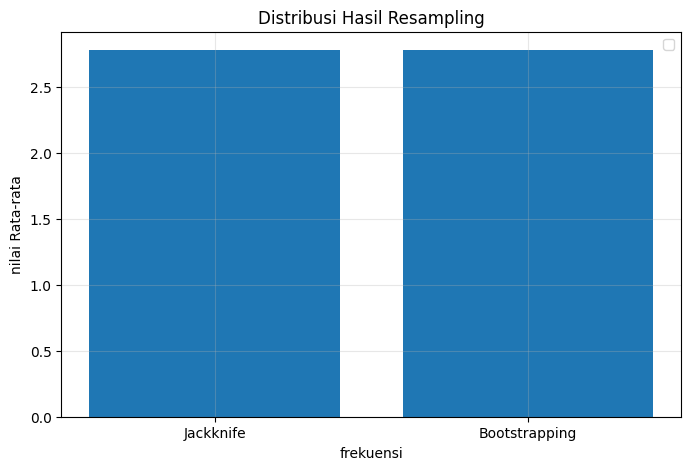

In [16]:
plt.figure(figsize=(8, 5))

plt.bar(
    ['Jackknife', 'Bootstrapping'],
    [rata_jackknife, rata_bootstrap]
)

plt.title('Distribusi Hasil Resampling')
plt.ylabel('nilai Rata-rata')
plt.xlabel('frekuensi')
plt.legend()
plt.grid(alpha=0.3)

plt.show()
